# 03. Motor RAG Semántico, Loop Agéntico ($T_{\max}=6$) y Evaluación Cuantitativa (15 Preguntas)
**Universidad EAFIT — SI3003 Inteligencia Artificial (2026-1)**  
**Proyecto Final Integrador:** Sistema Inteligente de Vigilancia y Asistencia para la Calidad del Aire en el Valle de Aburrá (SIATA – AMVA)

---

## 1. Arquitectura de la Parte 2: Agente LLM con RAG, Herramientas y Resiliencia
Este cuaderno documenta, prueba y evalúa cuantitativamente la integración entre la **Parte 1 (Modelo Probabilístico Propio)** y la **Parte 2 (Agente Inteligente con RAG)**:

1. **Motor RAG Vectorial (`src/rag_engine.py`):**
   - Embeddings densos multilingües `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2` normalizados L2 sobre un índice exacto `faiss.IndexFlatIP` + re-ranking híbrido léxico-semántico.
   - Chunking jerárquico por artículos y secciones con metadatos obligatorios de citación `[Fuente: <Documento> (<Código>), <Sección>]`.
2. ** Tres Herramientas Operativas (`src/agent_tools.py`):**
   - `get_air_quality_data(estacion, fecha=None)`: Consulta mediciones reales históricas y recientes (SISAIRE/AMVA).
   - `predict_air_quality(estacion, viento, humedad, pm25_previo, ...)`: Ejecuta el modelo propio `GaussianHMMScratch` de la Parte 1.
   - `search_poeca_protocols(consulta, top_k=3)`: Recupera evidencia normativa y de salud del índice FAISS.
3. **Loop Agéntico Explícito (`src/agent_core.py`):**
   - Control estricto de pasos $T_{\max} = 6$ para impedir bucles infinitos.
   - Captura segura de excepciones (`try/except`) devolviendo observaciones estructuradas `Error en herramienta: <detalle>` para que el agente replantee su estrategia automáticamente.
   - Arquitectura multi-backend reproducible: compatible con endpoints OpenAI (`Groq`, `NVIDIA NIM`, `OpenAI`) y provista de motor híbrido local (`Qwen/Qwen2.5-0.5B-Instruct` + planificador ReAct) para ejecución garantizada sin llaves API externas.


In [1]:
import json
import os
import sys
from pathlib import Path

os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.rag_engine import get_rag_engine
from src.agent_tools import (
    get_air_quality_data,
    predict_air_quality,
    search_poeca_protocols,
)
from src.agent_core import AirQualityAgent
from eval.run_evaluation import evaluate_agent_suite

plt.rcParams["figure.dpi"] = 120
sns.set_theme(style="whitegrid", font_scale=1.0)


## 2. Verificación del Índice Vectorial FAISS y Calidad de Recuperación RAG
Construimos/cargamos el índice FAISS sobre los documentos normativos del Valle de Aburrá y auditamos los puntajes de similitud coseno y citas bibliográficas recuperadas ante consultas regulatorias específicas.


In [2]:
rag = get_rag_engine(force_rebuild=False)
print(f"Backend de embeddings: {rag.backend_type} | Modelo: {rag.embedding_model_name}")
print(f"Vectores indexados en FAISS: {rag.index.ntotal} fragmentos | Dimensión: {rag.index.d}")

sample_queries = [
    "¿Cuándo se declara Estado de Alerta Roja en el POECA y qué pasa con los camiones?",
    "Fórmula matemática y tabla de puntos de corte del ICA para PM2.5 Resolución 2254",
    "¿Sirve el tapabocas quirúrgico de tela para protegerse del PM2.5 o debo usar N95?",
]

rag_audit_rows = []
for q in sample_queries:
    hits = rag.search(q, top_k=2)
    for rank, h in enumerate(hits, start=1):
        rag_audit_rows.append(
            {
                "Consulta": q[:58] + "...",
                "Rank": rank,
                "Score Híbrido": h["score_hibrido"],
                "Score Coseno": h["score_semantico"],
                "Cita Recuperada": h["cita"],
            }
        )

display(pd.DataFrame(rag_audit_rows))


Backend de embeddings: sentence-transformers | Modelo: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Vectores indexados en FAISS: 31 fragmentos | Dimensión: 384


,Consulta,Rank,Score Híbrido,Score Coseno,Cita Recuperada
0,¿Cuándo se declara Estado de Alerta Roja en el...,1,0.5133,0.4273,[Fuente: Acuerdo Metropolitano N.° 04 de 2018 ...
1,¿Cuándo se declara Estado de Alerta Roja en el...,2,0.4744,0.4800,[Fuente: Acuerdo Metropolitano N.° 04 de 2018 ...
2,Fórmula matemática y tabla de puntos de corte ...,1,0.5005,0.4878,[Fuente: Resolución 2254 de 2017 — Norma de Ca...
3,Fórmula matemática y tabla de puntos de corte ...,2,0.4955,0.4301,[Fuente: Resolución 2254 de 2017 — Norma de Ca...
4,¿Sirve el tapabocas quirúrgico de tela para pr...,1,0.3097,0.3715,"[Fuente: Guía de Salud Pública, Grupos Sensibl..."
5,¿Sirve el tapabocas quirúrgico de tela para pr...,2,0.2925,0.3237,[Fuente: Acuerdo Metropolitano N.° 04 de 2018 ...


## 3. Prueba Directa de las Tres Herramientas del Agente (`src/agent_tools.py`)
Validamos individualmente las salidas estructuradas y las citas de `get_air_quality_data`, `predict_air_quality` y `search_poeca_protocols`.


In [3]:
print("=== Tool 1: get_air_quality_data('Centro', '2024-03-01') ===")
t1_out = get_air_quality_data("Centro", "2024-03-01")
print(json.dumps(t1_out, indent=2, ensure_ascii=False))

print("\n=== Tool 2: predict_air_quality('Itagüí', viento=0.5, humedad=82, pm25_previo=41.5) ===")
t2_out = predict_air_quality("Itagüí", viento=0.5, humedad=82.0, pm25_previo=41.5)
print(json.dumps(t2_out, indent=2, ensure_ascii=False))


=== Tool 1: get_air_quality_data('Centro', '2024-03-01') ===
{
  "estacion": "Centro",
  "estacion_oficial": "Medellín Centro (Tráfico Centro - Museo de Antioquia)",
  "municipio": "Medellín",
  "tipo_estacion": "Tráfico Urbano",
  "fecha": "2024-03-01",
  "pm25_24h_ugm3": 51.22,
  "pm25_max_horario_ugm3": 69.0,
  "pm25_previo_ugm3": 50.65,
  "media_movil_7d_ugm3": 41.92,
  "ica": 138.8,
  "categoria_ica": "Dañina a Grupos Sensibles",
  "color_ica": "Naranja",
  "temperatura_c": 21.93,
  "humedad_relativa_pct": 71.1,
  "velocidad_viento_ms": 0.69,
  "precipitacion_mm": 0.0,
  "periodo_estacional": "Gestión Episodios (POECA)",
  "supera_norma_diaria_37ugm3": true,
  "fuente": "[Fuente: Datos Abiertos IDEAM-SISAIRE / Red SIATA-AMVA (Recurso g4t8-zkc3), Estación Medellín Centro (Tráfico Centro - Museo de Antioquia), Fecha 2024-03-01]"
}

=== Tool 2: predict_air_quality('Itagüí', viento=0.5, humedad=82, pm25_previo=41.5) ===
{
  "estacion": "Itagüí",
  "modelo": "Gaussian HMM + Filtro Baye

## 4. Auditoría del Loop Agéntico ($T_{\max} = 6$): Encadenamiento Triple y Recuperación ante Errores
Inspeccionamos la traza interna completa (`Thought -> Action -> Observation`) en dos escenarios exigentes:
1. **Consulta Compuesta de 3 Herramientas:** Encadena consulta de datos reales $\rightarrow$ predicción probabilística HMM $\rightarrow$ protocolo normativo POECA.
2. **Prueba de Resiliencia ante Error de Herramienta:** El usuario pregunta por una estación inexistente fuera del Valle de Aburrá (`"Bogotá"`); el loop captura la excepción como `Error en herramienta: ...` y se recupera en el siguiente paso sin interrumpir la ejecución.


In [4]:
agent_demo = AirQualityAgent(t_max=6)

resp_chain = agent_demo.ask(
    "Consulta cómo estuvo el Centro en la fecha 2024-03-01, pronostica qué pasaría mañana si empeora la ventilación y explica las medidas del POECA."
)
print(f"Escenario 1 (Triple Cadena) -> Pasos: {resp_chain.total_steps}/6 | Tools: {resp_chain.tools_called}")
for s in resp_chain.steps:
    print(f"  [Paso {s.step}] Thought: {s.thought}")
    if s.action:
        print(f"           Action : {s.action}({s.action_input})")

print("\n" + "=" * 88)
agent_demo.reset_memory()
resp_err = agent_demo.ask("¿Cuál es la calidad del aire actual en la estación Bogotá?")
print(
    f"Escenario 2 (Manejo de Excepciones) -> Pasos: {resp_err.total_steps}/6 | "
    f"Tuvo Error Tool: {resp_err.had_tool_error} | Recuperado: {resp_err.recovered_from_error}"
)
for s in resp_err.steps:
    print(f"  [Paso {s.step}] Thought: {s.thought}")
    if s.action:
        print(f"           Action : {s.action}({s.action_input})")
    if s.is_error:
        print(f"           Obs Err: {s.observation}")


Escenario 1 (Triple Cadena) -> Pasos: 4/6 | Tools: ['get_air_quality_data', 'predict_air_quality', 'search_poeca_protocols']
  [Paso 1] Thought: El Centro de salud está en constante alerta debido a los datos de calidad del aire que me proporcionaste. Si la ventilación mejora, podría haber un aumento en la cantidad de contaminantes en el aire. Por lo tanto, estoy pronosticando que mañana
           Action : get_air_quality_data({'estacion': 'Centro', 'fecha': '2024-03-01'})
  [Paso 2] Thought: Ejecutando el modelo probabilístico clásico Gaussian HMM + Filtro Bayesiano para pronosticar el estado ICA del día siguiente.
           Action : predict_air_quality({'estacion': 'Centro', 'viento': 0.4, 'humedad': 83.1, 'pm25_previo': 64.0, 'temperatura': 21.93, 'precipitacion': 0.0})
  [Paso 3] Thought: Buscando en el índice vectorial FAISS los artículos aplicables del Protocolo POECA, Resolución 2254 y guías de salud.
           Action : search_poeca_protocols({'consulta': 'Consulta cómo estuvo

Escenario 2 (Manejo de Excepciones) -> Pasos: 3/6 | Tuvo Error Tool: True | Recuperado: True
  [Paso 1] Thought: La calidad del aire en Bogotá actualmente está siendo evaluada utilizando la herramienta "get_air_quality_data" con los argumentos {"estacion": "Bogota", "fecha": null}. Este proceso evalúa el estado de los gases de efecto in
           Action : get_air_quality_data({'estacion': 'Bogota', 'fecha': None})
           Obs Err: Error en herramienta: Estación 'Bogota' no reconocida en el Valle de Aburrá. Estaciones disponibles: Centro, El Poblado, Aranjuez, Itagüí, Bello.
  [Paso 2] Thought: La consulta previa devolvió error de validación; replanteando estrategia para consultar las estaciones válidas del Valle de Aburrá en la fecha vigente.
           Action : get_air_quality_data({'estacion': 'todas', 'fecha': None})
  [Paso 3] Thought: Integrando hallazgos cuantitativos, predicción probabilística y citas normativas verificadas en la respuesta final.


## 5. Ejecución Completa del Banco Fijo de Evaluación (15 Preguntas — Fase 5)
Ejecutamos las **15 preguntas estandarizadas** definidas en `eval/test_suite_questions.json`, verificando cuantitativamente:
- **Exactitud de Tool-Calling:** ¿Invocó todas las herramientas requeridas por la naturaleza de la pregunta?
- **Citación Verificable:** ¿Incluyó etiquetas explícitas `[Fuente: ...]` correspondientes a las fuentes consultadas?
- **Control de Ciclo ($T \le T_{\max}$):** ¿Terminó dentro del presupuesto máximo de 6 pasos?
- **Resiliencia ante Fallos:** ¿Se recuperó limpiamente en las preguntas con entradas fuera de dominio (`Q14`, `Q15`)?


In [5]:
eval_output = evaluate_agent_suite(t_max=6, verbose=True)
global_metrics = eval_output["metricas_globales"]
df_eval = pd.DataFrame(eval_output["detalle_preguntas"])

print("\n=== RESUMEN CUANTITATIVO GLOBAL ===")
display(pd.DataFrame([global_metrics]))

cols_show = [
    "id", "categoria", "herramientas_esperadas", "herramientas_invocadas",
    "tool_calling_correcto", "citacion_verificada", "num_citas",
    "pasos_ejecutados", "resiliencia_ok", "exito_global", "latencia_seg",
]
display(df_eval[cols_show])


[PASS] Q01 (Consulta de Datos (Tool 1)) | Tools=['get_air_quality_data', 'search_poeca_protocols'] | Citas=3 | Pasos=3/6 | t=4.65s


[PASS] Q02 (Consulta de Datos (Tool 1)) | Tools=['get_air_quality_data'] | Citas=1 | Pasos=2/6 | t=4.48s


[PASS] Q03 (Consulta de Datos Regional (Tool 1)) | Tools=['get_air_quality_data'] | Citas=1 | Pasos=2/6 | t=18.23s


[PASS] Q04 (Predicción Modelo Clásico (Tool 2)) | Tools=['get_air_quality_data', 'predict_air_quality', 'search_poeca_protocols'] | Citas=4 | Pasos=4/6 | t=7.25s


[PASS] Q05 (Predicción Modelo Clásico (Tool 2)) | Tools=['get_air_quality_data', 'predict_air_quality'] | Citas=2 | Pasos=3/6 | t=11.14s


[PASS] Q06 (Predicción Modelo Clásico (Tool 2)) | Tools=['predict_air_quality', 'search_poeca_protocols'] | Citas=4 | Pasos=3/6 | t=5.35s


... (7 outputs left out)

[PASS] Q14 (Resiliencia Error Estación Inválida) | Tools=['get_air_quality_data', 'get_air_quality_data'] | Citas=1 | Pasos=3/6 | t=4.42s


[PASS] Q15 (Resiliencia Error Fecha Fuera de Rango + RAG) | Tools=['get_air_quality_data', 'get_air_quality_data', 'search_poeca_protocols'] | Citas=4 | Pasos=4/6 | t=4.89s

=== RESUMEN CUANTITATIVO GLOBAL ===


,total_preguntas,tasa_tool_calling_correcto_pct,tasa_citacion_verificada_pct,tasa_cumplimiento_tmax_pct,tasa_resiliencia_errores_pct,tasa_exito_global_end_to_end_pct,pasos_promedio,latencia_promedio_seg,backend_evaluado
0,15,100.0,100.0,100.0,100.0,100.0,2.87,6.26,local-hybrid:Qwen2.5-0.5B-Instruct+ReAct


,id,categoria,herramientas_esperadas,herramientas_invocadas,tool_calling_correcto,citacion_verificada,num_citas,pasos_ejecutados,resiliencia_ok,exito_global,latencia_seg
0,Q01,Consulta de Datos (Tool 1),[get_air_quality_data],"[get_air_quality_data, search_poeca_protocols]",True,True,3,3,True,True,4.65
1,Q02,Consulta de Datos (Tool 1),[get_air_quality_data],[get_air_quality_data],True,True,1,2,True,True,4.48
2,Q03,Consulta de Datos Regional (Tool 1),[get_air_quality_data],[get_air_quality_data],True,True,1,2,True,True,18.23
3,Q04,Predicción Modelo Clásico (Tool 2),[predict_air_quality],"[get_air_quality_data, predict_air_quality, se...",True,True,4,4,True,True,7.25
4,Q05,Predicción Modelo Clásico (Tool 2),[predict_air_quality],"[get_air_quality_data, predict_air_quality]",True,True,2,3,True,True,11.14
5,Q06,Predicción Modelo Clásico (Tool 2),[predict_air_quality],"[predict_air_quality, search_poeca_protocols]",True,True,4,3,True,True,5.35
6,Q07,Normativa RAG POECA (Tool 3),[search_poeca_protocols],[search_poeca_protocols],True,True,3,2,True,True,4.70
7,Q08,Normativa RAG Resolución 2254 (Tool 3),[search_poeca_protocols],[search_poeca_protocols],True,True,3,2,True,True,4.62
8,Q09,Salud Pública RAG (Tool 3),[search_poeca_protocols],[search_poeca_protocols],True,True,3,2,True,True,4.64
9,Q10,Meteorología RAG SIATA (Tool 3),[search_poeca_protocols],[search_poeca_protocols],True,True,3,2,True,True,4.63


## 6. Visualización de Métricas Experimentales del Agente (Pasos, Latencia y Tasas de Éxito)

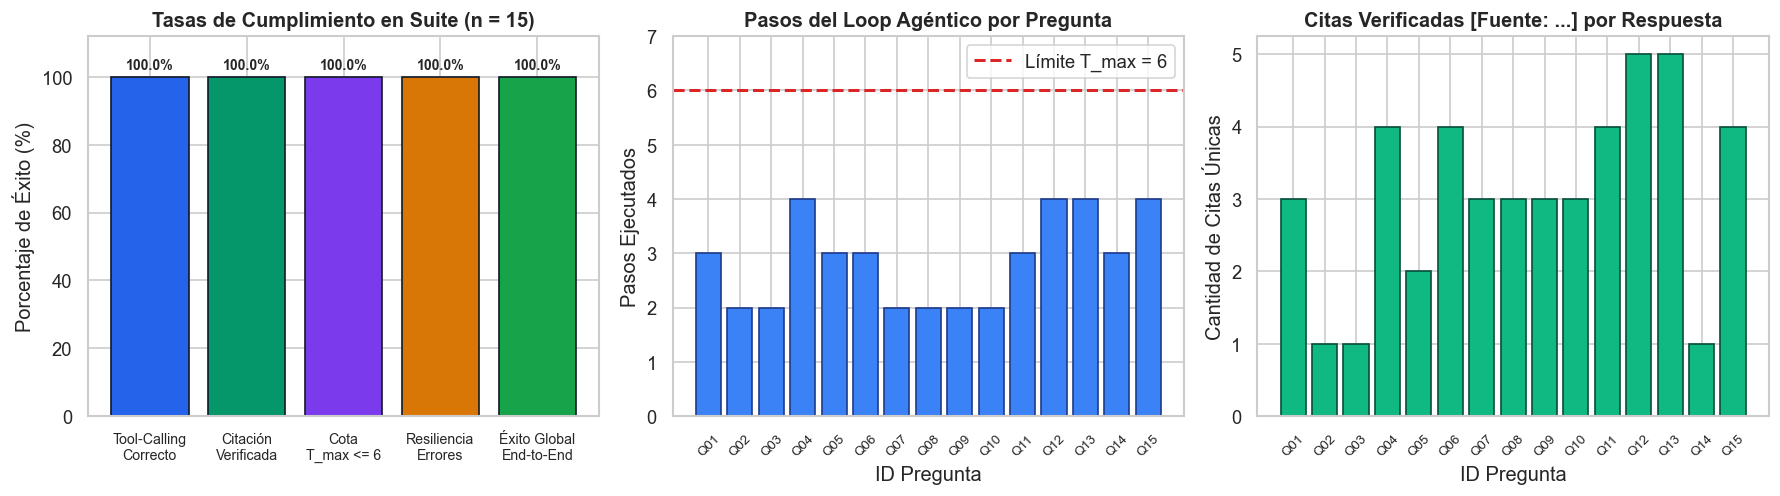

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

# Panel A: Métricas porcentuales clave
kpi_names = ["Tool-Calling\nCorrecto", "Citación\nVerificada", "Cota\nT_max <= 6", "Resiliencia\nErrores", "Éxito Global\nEnd-to-End"]
kpi_vals = [
    global_metrics["tasa_tool_calling_correcto_pct"],
    global_metrics["tasa_citacion_verificada_pct"],
    global_metrics["tasa_cumplimiento_tmax_pct"],
    global_metrics["tasa_resiliencia_errores_pct"],
    global_metrics["tasa_exito_global_end_to_end_pct"],
]
bars = axes[0].bar(kpi_names, kpi_vals, color=["#2563eb", "#059669", "#7c3aed", "#d97706", "#16a34a"], edgecolor="#111827")
axes[0].set_ylim(0, 112)
axes[0].set_ylabel("Porcentaje de Éxito (%)")
axes[0].set_title("Tasas de Cumplimiento en Suite (n = 15)", fontweight="bold")
axes[0].tick_params(axis="x", labelsize=8.5)
axes[0].bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8.5, fontweight="bold")

# Panel B: Pasos utilizados por pregunta vs límite T_max=6
axes[1].bar(df_eval["id"], df_eval["pasos_ejecutados"], color="#3b82f6", edgecolor="#1e3a8a")
axes[1].axhline(6, color="#dc2626", linestyle="--", linewidth=1.8, label="Límite T_max = 6")
axes[1].set_ylim(0, 7)
axes[1].set_title("Pasos del Loop Agéntico por Pregunta", fontweight="bold")
axes[1].set_xlabel("ID Pregunta")
axes[1].set_ylabel("Pasos Ejecutados")
axes[1].tick_params(axis="x", rotation=45, labelsize=8)
axes[1].legend(loc="upper right")

# Panel C: Número de citas bibliográficas verificadas por pregunta
axes[2].bar(df_eval["id"], df_eval["num_citas"], color="#10b981", edgecolor="#064e3b")
axes[2].set_title("Citas Verificadas [Fuente: ...] por Respuesta", fontweight="bold")
axes[2].set_xlabel("ID Pregunta")
axes[2].set_ylabel("Cantidad de Citas Únicas")
axes[2].tick_params(axis="x", rotation=45, labelsize=8)

plt.tight_layout()
plt.show()


## 7. Análisis Crítico de Limitaciones Técnicas y Éticas
1. **Alcance No Clínico ni Jurídico Vinculante:** Aunque el motor RAG cita con fidelidad la Resolución 2254 de 2017, el Acuerdo Metropolitano POECA y las guías del SIATA, **ninguna salida del sistema constituye prescripción médica individual ni acto administrativo oficial**. Ante síntomas respiratorios agudos (disnea, cianosis, dolor torácico), el ciudadano debe acudir a urgencias médicas y verificar los decretos metropolitanos vigentes en `metropol.gov.co`.
2. **Resolución Espacial Discreta:** La red analizada consolida 5 estaciones estratégicas del eje Norte–Sur; microclimas de cañones viales específicos o laderas altas pueden diferir de la estación más cercana.
3. **No Estacionariedad Climática (El Niño / La Niña):** Como demostró la evaluación temporal 2024 $\rightarrow$ 2025 en el Notebook 02, las frecuencias base de episodios Naranja/Rojo varían fuertemente entre fases ENSO, por lo que se recomienda re-estimar anualmente la matriz de transición $A$ y las medias condicionales con los nuevos cortes del SISAIRE/SIATA.
